# Llama 3.2-3B Energy Ablation — Simple

**CSE407 Green Computing · T4 GPU · 10 Hz pynvml power monitoring**

| Config | Weights | Eviction | KV Cache |
|--------|---------|----------|----------|
| C0 | FP16 | None | FP16 |
| C1 | AWQ 4-bit | None | FP16 |
| C2 | AWQ 4-bit | PyramidKV | FP16 |
| C3 | AWQ 4-bit | None | TurboQuant 4-bit |
| C4 | AWQ 4-bit | PyramidKV | TurboQuant 4-bit |

> **Contexts**: 512, 2048, 4096 (not 8192 — T4 lacks FlashAttention-2, and the 8192²
> float32 attention matrix alone is 6 GiB, exceeding available VRAM even with AWQ).

## 1. Install
Run once, then **Runtime → Restart session**.

In [1]:
!pip install -q autoawq==0.2.9 gptqmodel turboquant
!pip install -q transformers accelerate nvidia-ml-py pandas matplotlib scipy
print('Done — restart the Colab session (Runtime -> Restart session) before continuing.')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.3/74.3 kB 4.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 33.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 6.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.8/121.8 kB 7.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.8/97.8 kB 11.9 MB/s eta 0:00:00
  Installing build

## 2. Imports & Configuration

In [1]:
import gc, os, threading, time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

# Force memory-efficient SDPA on T4 (which lacks FlashAttention-2)
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

import pynvml
from transformers import AutoModelForCausalLM, AutoTokenizer, DynamicCache, set_seed
from transformers.models.llama.modeling_llama import LlamaAttention, apply_rotary_pos_emb, repeat_kv, eager_attention_forward
from transformers.modeling_utils import ALL_ATTENTION_FUNCTIONS
from turboquant import TurboQuantCache

# ── Hardware ──
pynvml.nvmlInit()
HANDLE = pynvml.nvmlDeviceGetHandleByIndex(0)

# ── Config ──
SEED = 407
MODEL_BF16 = 'unsloth/Llama-3.2-3B-Instruct'
MODEL_AWQ  = 'casperhansen/llama-3.2-3b-instruct-awq'
CONTEXTS   = [512, 2048, 4096]
REPETITIONS = 3

set_seed(SEED)
torch.manual_seed(SEED); np.random.seed(SEED)

assert torch.cuda.is_available(), 'CUDA GPU required.'
PROPS = torch.cuda.get_device_properties(0)
print(f'GPU: {PROPS.name} | VRAM: {PROPS.total_memory/2**30:.1f} GB | SM: {PROPS.major}.{PROPS.minor}')

GPU: Tesla T4 | VRAM: 14.6 GB | SM: 7.5


## 3. GPU Power Monitor & Helpers

In [2]:
class GPUMonitor:
    """Background NVML power poller at 100 ms."""

    def __init__(self, interval_s: float = 0.1):
        self.interval_s = interval_s
        self.samples: list[dict] = []
        self._running = False
        self._thread = None
        self._t0 = 0.0

    def _poll(self):
        deadline = self._t0
        while self._running:
            try:
                mem = pynvml.nvmlDeviceGetMemoryInfo(HANDLE)
                self.samples.append({
                    't_s': time.perf_counter() - self._t0,
                    'power_w': pynvml.nvmlDeviceGetPowerUsage(HANDLE) / 1000.0,
                    'temp_c': pynvml.nvmlDeviceGetTemperature(HANDLE, pynvml.NVML_TEMPERATURE_GPU),
                    'mem_mb': mem.used / 2**20,
                })
            except Exception:
                pass
            deadline += self.interval_s
            time.sleep(max(0.0, deadline - time.perf_counter()))

    def start(self):
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
        self.samples.clear()
        self._running = True
        self._t0 = time.perf_counter()
        self._thread = threading.Thread(target=self._poll, daemon=True)
        self._thread.start()

    def stop(self) -> dict:
        torch.cuda.synchronize()
        self._running = False
        if self._thread:
            self._thread.join(timeout=2)
        vals = [s for s in self.samples if 'power_w' in s]
        if len(vals) < 2:
            raise RuntimeError(f'Only {len(vals)} valid power samples.')
        t = np.array([s['t_s'] for s in vals])
        p = np.array([s['power_w'] for s in vals])
        return {
            'avg_power_w': float(np.mean(p)),
            'max_power_w': float(np.max(p)),
            'energy_j': float(np.trapezoid(p, t)),
            'n_samples': len(vals),
            'peak_mem_mb': max(s.get('mem_mb', 0) for s in vals),
        }


def clear_gpu():
    """Aggressively free GPU memory."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.synchronize()
        # Force Python GC a second time after CUDA sync
        gc.collect()
        torch.cuda.empty_cache()


def free_result_tensors(result: dict):
    """Delete any tensor references in a result dict."""
    for key in list(result.keys()):
        val = result[key]
        if isinstance(val, torch.Tensor):
            del result[key]
            del val

print('Monitor ready.')

Monitor ready.


## 4. NIAH Test Data

In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_BF16, trust_remote_code=True)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token_id = tokenizer.eos_token_id

NEEDLE = 'The secret project code name is SHADOW-8821.'
FILLER = (
    'The history of computing is a fascinating journey through time. '
    'From the earliest mechanical calculators to modern quantum computers, '
    'humanity has constantly pushed the boundaries of what machines can do. '
)


def make_niah_input(ctx_len: int, depth: float = 0.5, seed: int = 0) -> dict:
    rng = np.random.RandomState(SEED * 1000 + seed)
    messages = [
        {'role': 'system', 'content': 'Extract the exact information requested.'},
        {'role': 'user', 'content': (
            'Read the document below. Complete the final statement using '
            'only the code name from the document. Return the code name and nothing else.\n\n'
            '<DOC>\n{HAYSTACK}\n</DOC>\n\nThe secret project code name is'
        )},
    ]
    needle_ids = tokenizer.encode(f'\n{NEEDLE}\n', add_special_tokens=False)
    filler_unit = tokenizer.encode(FILLER, add_special_tokens=False)
    template = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    template_ids = tokenizer.encode(template.replace('{HAYSTACK}', ''), add_special_tokens=False)
    budget = ctx_len - len(template_ids) - len(needle_ids)
    assert budget >= 16, f'Context {ctx_len} too short.'
    before = max(0, min(budget, int(budget * depth)))
    after = budget - before
    fb = (filler_unit * (before // len(filler_unit) + 1))[:before]
    fa = (filler_unit * (after // len(filler_unit) + 1))[:after]
    haystack = tokenizer.decode(fb) + f'\n{NEEDLE}\n' + tokenizer.decode(fa)
    text = template.replace('{HAYSTACK}', haystack)
    ids = tokenizer.encode(text, add_special_tokens=False)
    if len(ids) < ctx_len:
        ids += [tokenizer.pad_token_id] * (ctx_len - len(ids))
    ids = ids[:ctx_len]
    return {
        'input_ids': torch.tensor([ids], dtype=torch.long),
        'attention_mask': torch.ones((1, ctx_len), dtype=torch.long),
    }


def check_niah(response: str) -> bool:
    return 'shadow-8821' in response.lower()


for ctx in CONTEXTS:
    inp = make_niah_input(ctx)
    assert inp['input_ids'].shape[1] == ctx
print('Token counts verified.')

config.json:   0%|          | 0.00/890 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.7k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.2M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/3.83k [00:00<?, ?B/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Token counts verified.


## 5. Model Loaders

In [4]:
def load_fp16():
    clear_gpu()
    return AutoModelForCausalLM.from_pretrained(
        MODEL_BF16, torch_dtype=torch.float16, device_map={'': 0},
        attn_implementation='sdpa', trust_remote_code=True,
    ).eval()


def load_awq():
    clear_gpu()
    return AutoModelForCausalLM.from_pretrained(
        MODEL_AWQ, device_map={'': 0},
        attn_implementation='sdpa', trust_remote_code=True,
    ).eval()

print('Loaders ready.')

Loaders ready.


## 6. PyramidKV Implementation

Simple, clean token eviction. Early layers get more budget, late layers less.
Only activates when `use_pkv=True`.

In [5]:
# ─── PyramidKV: simple clean token eviction ────────────────────────────────────
# Llama 3.2-3B: 28 layers, 24 Q / 8 KV heads, head_dim=128
# Budget: avg 1024 tokens per layer, pyramidal (early > late)

WINDOW = 32      # observation window for attention scoring
SINK = 4         # always keep first 4 tokens (attention sinks)

def _build_budgets(n_layers=28, avg=1024):
    ramp = np.linspace(1.5, 0.5, n_layers)
    w = ramp / ramp.sum()
    budgets = np.round(w * n_layers * avg).astype(int)
    budgets[-1] += n_layers * avg - budgets.sum()
    return budgets.tolist()

PYRAMID_BUDGETS = _build_budgets()
_ORIG_FORWARD = LlamaAttention.forward


def _pkv_forward(
    self,
    hidden_states: 'torch.Tensor',
    position_embeddings: 'tuple | None' = None,
    attention_mask: 'torch.Tensor | None' = None,
    past_key_values: 'Cache | None' = None,
    **kwargs,
) -> 'tuple':
    """PyramidKV: mirrors LlamaAttention.forward + eviction after cache update."""
    input_shape = hidden_states.shape[:-1]
    hidden_shape = (*input_shape, -1, self.head_dim)

    query_states = self.q_proj(hidden_states).view(hidden_shape).transpose(1, 2)
    key_states = self.k_proj(hidden_states).view(hidden_shape).transpose(1, 2)
    value_states = self.v_proj(hidden_states).view(hidden_shape).transpose(1, 2)

    cos, sin = position_embeddings
    query_states, key_states = apply_rotary_pos_emb(query_states, key_states, cos, sin)

    if past_key_values is not None:
        key_states, value_states = past_key_values.update(key_states, value_states, self.layer_idx)

    # ── PyramidKV eviction ──
    budget = PYRAMID_BUDGETS[self.layer_idx]
    cache_len = key_states.shape[2]
    if past_key_values is not None and cache_len > budget and query_states.shape[-2] >= WINDOW:
        try:
            obs = min(WINDOW, query_states.shape[-2])
            recent_q = query_states[:, :, -obs:, :]
            n_groups = self.num_key_value_groups
            # GQA: repeat KV transiently for scoring
            k_score = repeat_kv(key_states, n_groups) if n_groups > 1 else key_states
            attn = torch.matmul(recent_q, k_score.transpose(2, 3)) * self.scaling
            # Causal mask for observation window (matching official PyramidKV)
            causal = torch.triu(torch.full((obs, obs), float('-inf'), device=attn.device, dtype=attn.dtype), diagonal=1)
            attn[:, :, -obs:, -obs:] += causal[None, None, :, :]
            # Softmax, then sum over window queries, then reduce to kv-heads
            attn = F.softmax(attn, dim=-1, dtype=torch.float32).to(query_states.dtype)
            attn_sum = attn[:, :, -obs:, :-obs].sum(dim=-2)  # (1, n_q_heads, past_len)
            past_len = cache_len - obs
            if n_groups > 1:
                attn_sum = attn_sum.reshape(1, key_states.shape[1], n_groups, past_len).mean(dim=2)
            scores_flat = attn_sum.sum(dim=1)  # (1, past_len)
            scores_flat[:, :SINK] = 1e9
            capacity = min(budget - obs, past_len)
            _, topk = torch.topk(scores_flat, capacity, dim=-1)
            keep, _ = torch.sort(topk, dim=-1)
            # Gather past + concat recent (matching official PyramidKV)
            k_past = key_states[:, :, keep[0], :].contiguous()
            v_past = value_states[:, :, keep[0], :].contiguous()
            k_recent = key_states[:, :, -obs:, :]
            v_recent = value_states[:, :, -obs:, :]
            key_states = torch.cat([k_past, k_recent], dim=2)
            value_states = torch.cat([v_past, v_recent], dim=2)
            past_key_values.key_cache[self.layer_idx] = key_states
            past_key_values.value_cache[self.layer_idx] = value_states
        except AttributeError:
            pass

    # Delegate attention to standard interface (handles SDPA/eager/flash correctly)
    attention_interface = ALL_ATTENTION_FUNCTIONS.get_interface(
        self.config._attn_implementation, eager_attention_forward)
    attn_output, attn_weights = attention_interface(
        self, query_states, key_states, value_states,
        attention_mask, dropout=0.0, scaling=self.scaling, **kwargs)

    attn_output = attn_output.reshape(*input_shape, -1).contiguous()
    attn_output = self.o_proj(attn_output)
    return attn_output, attn_weights


def enable_pyramidkv():
    LlamaAttention.forward = _pkv_forward


def disable_pyramidkv():
    LlamaAttention.forward = _ORIG_FORWARD


# ─── Experiment runner ────────────────────────────────────────
def run_one(model, config: str, ctx: int, *, use_pkv: bool = False,
            use_tq: bool = False, max_new: int = 24, run_id: int = 0) -> dict:
    """Run one NIAH test with GPU power monitoring."""
    clear_gpu()
    inputs_cpu = make_niah_input(ctx, seed=run_id)
    inputs = {k: v.to(model.device) for k, v in inputs_cpu.items()}

    cache = TurboQuantCache(bits=4) if use_tq else DynamicCache()

    if use_pkv:
        enable_pyramidkv()

    monitor = GPUMonitor()
    monitor.start()
    t0 = time.perf_counter()

    prefill_s = decode_s = total_s = 0.0
    ppl = 0.0
    out_ids = None
    response = ''
    _locals = {}

    try:
        with torch.inference_mode():
            # ── Prefill ──
            t_pf = time.perf_counter()
            out = _locals['out'] = model(**inputs, past_key_values=cache, use_cache=True)
            torch.cuda.synchronize()
            prefill_s = time.perf_counter() - t_pf

            sl = _locals['sl'] = out.logits[0, :-1, :].contiguous()
            lb = _locals['lb'] = inputs['input_ids'][0, 1:].contiguous()
            ppl = float(torch.exp(F.cross_entropy(sl, lb)))
            del sl, lb

            # ── Decode ──
            nt = _locals['nt'] = out.logits[:, -1, :].argmax(dim=-1, keepdim=True)
            gen = _locals['gen'] = []
            attn = _locals['attn'] = inputs['attention_mask']
            t_dc = time.perf_counter()
            for _ in range(max_new):
                gen.append(nt)
                if nt.item() == tokenizer.eos_token_id:
                    break
                attn = torch.cat([attn, torch.ones((1, 1), dtype=torch.long, device=model.device)], dim=1)
                out = model(input_ids=nt, attention_mask=attn, past_key_values=cache, use_cache=True)
                nt = out.logits[:, -1, :].argmax(dim=-1, keepdim=True)
            torch.cuda.synchronize()
            decode_s = time.perf_counter() - t_dc

        total_s = time.perf_counter() - t0
        power = monitor.stop()
        out_ids = torch.cat(gen, dim=1)[0] if gen else torch.empty(0, dtype=torch.long)
        response = tokenizer.decode(out_ids.tolist(), skip_special_tokens=True)
    except torch.cuda.OutOfMemoryError:
        monitor.stop()
        if use_pkv:
            disable_pyramidkv()
        return {'config': config, 'context': ctx, 'run': run_id, 'correct': None, 'oom': True}
    finally:
        if use_pkv:
            disable_pyramidkv()
        for name in ['cache', 'inputs', 'inputs_cpu', 'out', 'gen', 'attn', 'nt', 'sl', 'lb']:
            if name in _locals:
                del _locals[name]
        clear_gpu()

    return {
        'config': config, 'context': ctx, 'run': run_id,
        'prefill_s': prefill_s, 'decode_s': decode_s, 'total_s': total_s,
        'output_tokens': int(out_ids.numel()), 'ppl': ppl,
        'correct': check_niah(response),
        'avg_power_w': power['avg_power_w'],
        'max_power_w': power['max_power_w'],
        'energy_j': power['energy_j'],
        'vram_peak_mb': torch.cuda.max_memory_allocated() / 2**20,
        'n_samples': power['n_samples'],
        'nvml_peak_mb': power['peak_mem_mb'],
    }

print('Runner ready.')

Runner ready.


## 7. Pre-flight Diagnostics

Verify PyramidKV budgets, attention interface, and model structure before running experiments.

In [6]:
# === Pre-flight Diagnostics ===
print("--- PyramidKV Budgets (28 layers, avg=1024) ---")
for i in range(0, 28, 7):
    print(f"  L{i:02d}-L{min(i+6, 27):02d}: {PYRAMID_BUDGETS[i:i+7]}")

print(f"  Total budget: {sum(PYRAMID_BUDGETS)}, Avg: {sum(PYRAMID_BUDGETS)/28:.0f}")
print()

print("--- Eviction triggers per context ---")
for ctx in CONTEXTS:
    for layer in [0, 13, 27]:
        b = PYRAMID_BUDGETS[layer]
        evicts = "EVICT" if ctx > b else "keep"
        print(f"  ctx={ctx:4d}  L{layer:02d}  budget={b:4d}  => {evicts}")

print()
print("--- Attention: delegated to standard transformers interface ---")
print("  (no manual mask handling => no SDPA boolean mask bug)")

--- PyramidKV Budgets (28 layers, avg=1024) ---
  L00-L06: [1536, 1498, 1460, 1422, 1384, 1346, 1308]
  L07-L13: [1271, 1233, 1195, 1157, 1119, 1081, 1043]
  L14-L20: [1005, 967, 929, 891, 853, 815, 777]
  L21-L27: [740, 702, 664, 626, 588, 550, 512]
  Total budget: 28672, Avg: 1024

--- Eviction triggers per context ---
  ctx= 512  L00  budget=1536  => keep
  ctx= 512  L13  budget=1043  => keep
  ctx= 512  L27  budget= 512  => keep
  ctx=2048  L00  budget=1536  => EVICT
  ctx=2048  L13  budget=1043  => EVICT
  ctx=2048  L27  budget= 512  => EVICT
  ctx=4096  L00  budget=1536  => EVICT
  ctx=4096  L13  budget=1043  => EVICT
  ctx=4096  L27  budget= 512  => EVICT

--- Attention: delegated to standard transformers interface ---
  (no manual mask handling => no SDPA boolean mask bug)


## 7a. C0: FP16 Baseline
Runs in its own cell. Model unloaded after completion.

> C0 @ 4096 may OOM on T4 (6.0 GB model + 1.5 GB attention matrix = borderline).
> If OOM occurs, skip this context — it's expected hardware constraint.

In [7]:
results_c0 = []

model = load_fp16()
print(f'FP16 model loaded. VRAM used: {torch.cuda.memory_allocated()/2**30:.1f} GB')

for ctx in CONTEXTS:
    for r in range(REPETITIONS):
        try:
            row = run_one(model, 'C0', ctx, run_id=r)
            results_c0.append(row)
            if row.get('oom'):
                print(f'  C0 @ {ctx} rep={r}: OOM')
            else:
                ok = 'OK' if row['correct'] else 'FAIL'
                print(f"  C0 @ {ctx} rep={r}: {row['total_s']:.1f}s, {row['energy_j']:.1f}J, NIAH={ok}")
        except torch.cuda.OutOfMemoryError:
            clear_gpu()
            print(f'  C0 @ {ctx} rep={r}: OOM')

del model; clear_gpu()
print(f'C0 done. {len(results_c0)} runs collected.')

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/20.9k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/234 [00:00<?, ?B/s]

FP16 model loaded. VRAM used: 6.0 GB
  C0 @ 512 rep=0: 1.8s, 71.1J, NIAH=OK
  C0 @ 512 rep=1: 0.6s, 33.5J, NIAH=OK
  C0 @ 512 rep=2: 0.6s, 32.8J, NIAH=OK
  C0 @ 2048 rep=0: 2.9s, 172.4J, NIAH=OK
  C0 @ 2048 rep=1: 2.0s, 132.0J, NIAH=OK
  C0 @ 2048 rep=2: 2.0s, 125.7J, NIAH=OK
  C0 @ 4096 rep=0: 5.5s, 361.1J, NIAH=OK
  C0 @ 4096 rep=1: 5.5s, 361.2J, NIAH=OK
  C0 @ 4096 rep=2: 5.5s, 369.0J, NIAH=OK
C0 done. 9 runs collected.


## 7b. C1–C4: AWQ Configurations
AWQ model loaded once, reused across all four compressed configs.

In [8]:
results_awq = []

model = load_awq()
print(f'AWQ model loaded. VRAM used: {torch.cuda.memory_allocated()/2**30:.1f} GB')

for cfg_name, use_pkv, use_tq in [
    ('C1', False, False),   # AWQ only
    ('C2', True,  False),   # AWQ + PyramidKV
    ('C3', False, True),    # AWQ + TurboQuant
    ('C4', True,  True),    # AWQ + PyramidKV + TurboQuant
]:
    print(f'\n{"="*50}\n{cfg_name}\n{"="*50}')
    for ctx in CONTEXTS:
        for r in range(REPETITIONS):
            try:
                row = run_one(model, cfg_name, ctx, use_pkv=use_pkv, use_tq=use_tq, run_id=r)
                results_awq.append(row)
                if row.get('oom'):
                    print(f'  {cfg_name} @ {ctx} rep={r}: OOM')
                else:
                    ok = 'OK' if row['correct'] else 'FAIL'
                    print(f"  {cfg_name} @ {ctx} rep={r}: {row['total_s']:.1f}s, {row['energy_j']:.1f}J, NIAH={ok}")
            except torch.cuda.OutOfMemoryError:
                clear_gpu()
                print(f'  {cfg_name} @ {ctx} rep={r}: OOM — skipping')
            except Exception as e:
                clear_gpu()
                print(f'  {cfg_name} @ {ctx} rep={r}: ERROR — {type(e).__name__}: {e}')

del model; clear_gpu()
print(f'C1–C4 done. {len(results_awq)} runs collected.')

config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.25G [00:00<?, ?B/s]

WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.


INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True,max_split_size_mb:256,garbage_collection_threshold:0.7' for memory saving.


INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.          


INFO  

┌─────────────┐    ┌────────────────────────┐    ┌────────────┐    ┌─────────┐
│ GPT-QModel  │ -> │ ▓▓▓▓▓▓▓▓▓▓▓▓ 16bit     │ -> │ ▒▒▒▒ 8bit  │ -> │ ░░ 4bit │
└─────────────┘    └────────────────────────┘    └────────────┘    └─────────┘
GPT-QModel   : 7.1.0
Transformers : 5.12.1
Torch        : 2.11.0+cu128
Triton       : 3.6.0


... (4 outputs left out)

Loading weights:   0%|          | 0/646 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

INFO  gc.collect() reclaimed 28 objects in 0.291s                              


AWQ model loaded. VRAM used: 2.2 GB

C1
  C1 @ 512 rep=0: 0.8s, 39.0J, NIAH=OK
  C1 @ 512 rep=1: 0.8s, 43.6J, NIAH=OK
  C1 @ 512 rep=2: 0.7s, 39.4J, NIAH=OK
  C1 @ 2048 rep=0: 1.9s, 124.7J, NIAH=OK
  C1 @ 2048 rep=1: 1.9s, 129.1J, NIAH=OK
  C1 @ 2048 rep=2: 1.9s, 125.8J, NIAH=OK
  C1 @ 4096 rep=0: 5.3s, 355.2J, NIAH=OK
  C1 @ 4096 rep=1: 5.4s, 353.6J, NIAH=OK
  C1 @ 4096 rep=2: 5.4s, 362.2J, NIAH=OK

C2
  C2 @ 512 rep=0: 0.7s, 39.8J, NIAH=OK
  C2 @ 512 rep=1: 0.7s, 34.0J, NIAH=OK
  C2 @ 512 rep=2: 0.9s, 44.9J, NIAH=OK
  C2 @ 2048 rep=0: 1.4s, 81.7J, NIAH=FAIL
  C2 @ 2048 rep=1: 1.3s, 80.8J, NIAH=FAIL
  C2 @ 2048 rep=2: 1.3s, 80.4J, NIAH=FAIL
  C2 @ 4096 rep=0: 2.3s, 156.3J, NIAH=FAIL
  C2 @ 4096 rep=1: 2.3s, 156.9J, NIAH=FAIL
  C2 @ 4096 rep=2: 2.3s, 156.5J, NIAH=FAIL

C3
  C3 @ 512 rep=0: 1.2s, 65.4J, NIAH=OK
  C3 @ 512 rep=1: 1.2s, 56.3J, NIAH=OK
  C3 @ 512 rep=2: 1.0s, 55.8J, NIAH=OK
  C3 @ 2048 rep=0: 2.6s, 167.2J, NIAH=OK
  C3 @ 2048 rep=1: 2.5s, 161.2J, NIAH=OK
  C3 @ 2048 rep=2:

## 7c. Combine & Save Results

In [9]:
all_results = results_c0 + results_awq
df = pd.DataFrame(all_results)
df.to_csv('ablation_results.csv', index=False)
print(f'Saved {len(df)} runs to ablation_results.csv')
display(df.groupby(['config', 'context'])[['total_s', 'energy_j', 'correct']].mean().round(2))

Saved 45 runs to ablation_results.csv


total_s  energy_j  correct
config context                            
C0     512         0.98     45.78      1.0
       2048        2.28    143.34      1.0
       4096        5.50    363.77      1.0
C1     512         0.78     40.67      1.0
       2048        1.93    126.54      1.0
       4096        5.37    357.00      1.0
C2     512         0.75     39.57      1.0
       2048        1.30     80.96      0.0
       4096        2.33    156.57      0.0
C3     512         1.13     59.17      1.0
       2048        2.59    169.10      1.0
       4096        5.53    366.41      0.0
C4     512         1.05     57.63      1.0
       2048        2.24    144.18      1.0
       4096        3.08    200.83      0.0

## 8. Results & Visualizations

In [10]:
# === Log Summary ===
print("=== NIAH & Energy Verification ===")
for cfg in ["C1", "C2"]:
    for ctx in CONTEXTS:
        sub = df[(df.config == cfg) & (df.context == ctx)]
        acc = sub.correct.mean() if len(sub) else 0
        eng = sub.energy_j.mean() if len(sub) else 0
        print(f"  {cfg} @ {ctx:4d}:  NIAH={acc*100:.0f}%  Energy={eng:.0f}J")

print()
print("=== Energy pivot (J) ===")
pivot = df.groupby(["config", "context"]).energy_j.mean().round(0).unstack()
print(pivot.to_string())

print()
print("=== NIAH accuracy ===")
acc_pivot = (df.groupby(["config", "context"]).correct.mean() * 100).round(0).unstack()
print(acc_pivot.to_string())

print()
print("=== Expected behavior ===")
print("  C2@512: should match C1@512 (no eviction at 512, budgets all >=512)")
print("  C2@2048: energy lower than C1 (deep layers compress prefill cache)")
print("  C2@4096: energy much lower, NIAH may degrade (heavy compression)")

=== NIAH & Energy Verification ===
  C1 @  512:  NIAH=100%  Energy=41J
  C1 @ 2048:  NIAH=100%  Energy=127J
  C1 @ 4096:  NIAH=100%  Energy=357J
  C2 @  512:  NIAH=100%  Energy=40J
  C2 @ 2048:  NIAH=0%  Energy=81J
  C2 @ 4096:  NIAH=0%  Energy=157J

=== Energy pivot (J) ===
context  512    2048   4096
config                     
C0       46.0  143.0  364.0
C1       41.0  127.0  357.0
C2       40.0   81.0  157.0
C3       59.0  169.0  366.0
C4       58.0  144.0  201.0

=== NIAH accuracy ===
context   512    2048   4096
config                      
C0       100.0  100.0  100.0
C1       100.0  100.0  100.0
C2       100.0    0.0    0.0
C3       100.0  100.0    0.0
C4       100.0  100.0    0.0

=== Expected behavior ===
  C2@512: should match C1@512 (no eviction at 512, budgets all >=512)
  C2@2048: energy lower than C1 (deep layers compress prefill cache)
  C2@4096: energy much lower, NIAH may degrade (heavy compression)


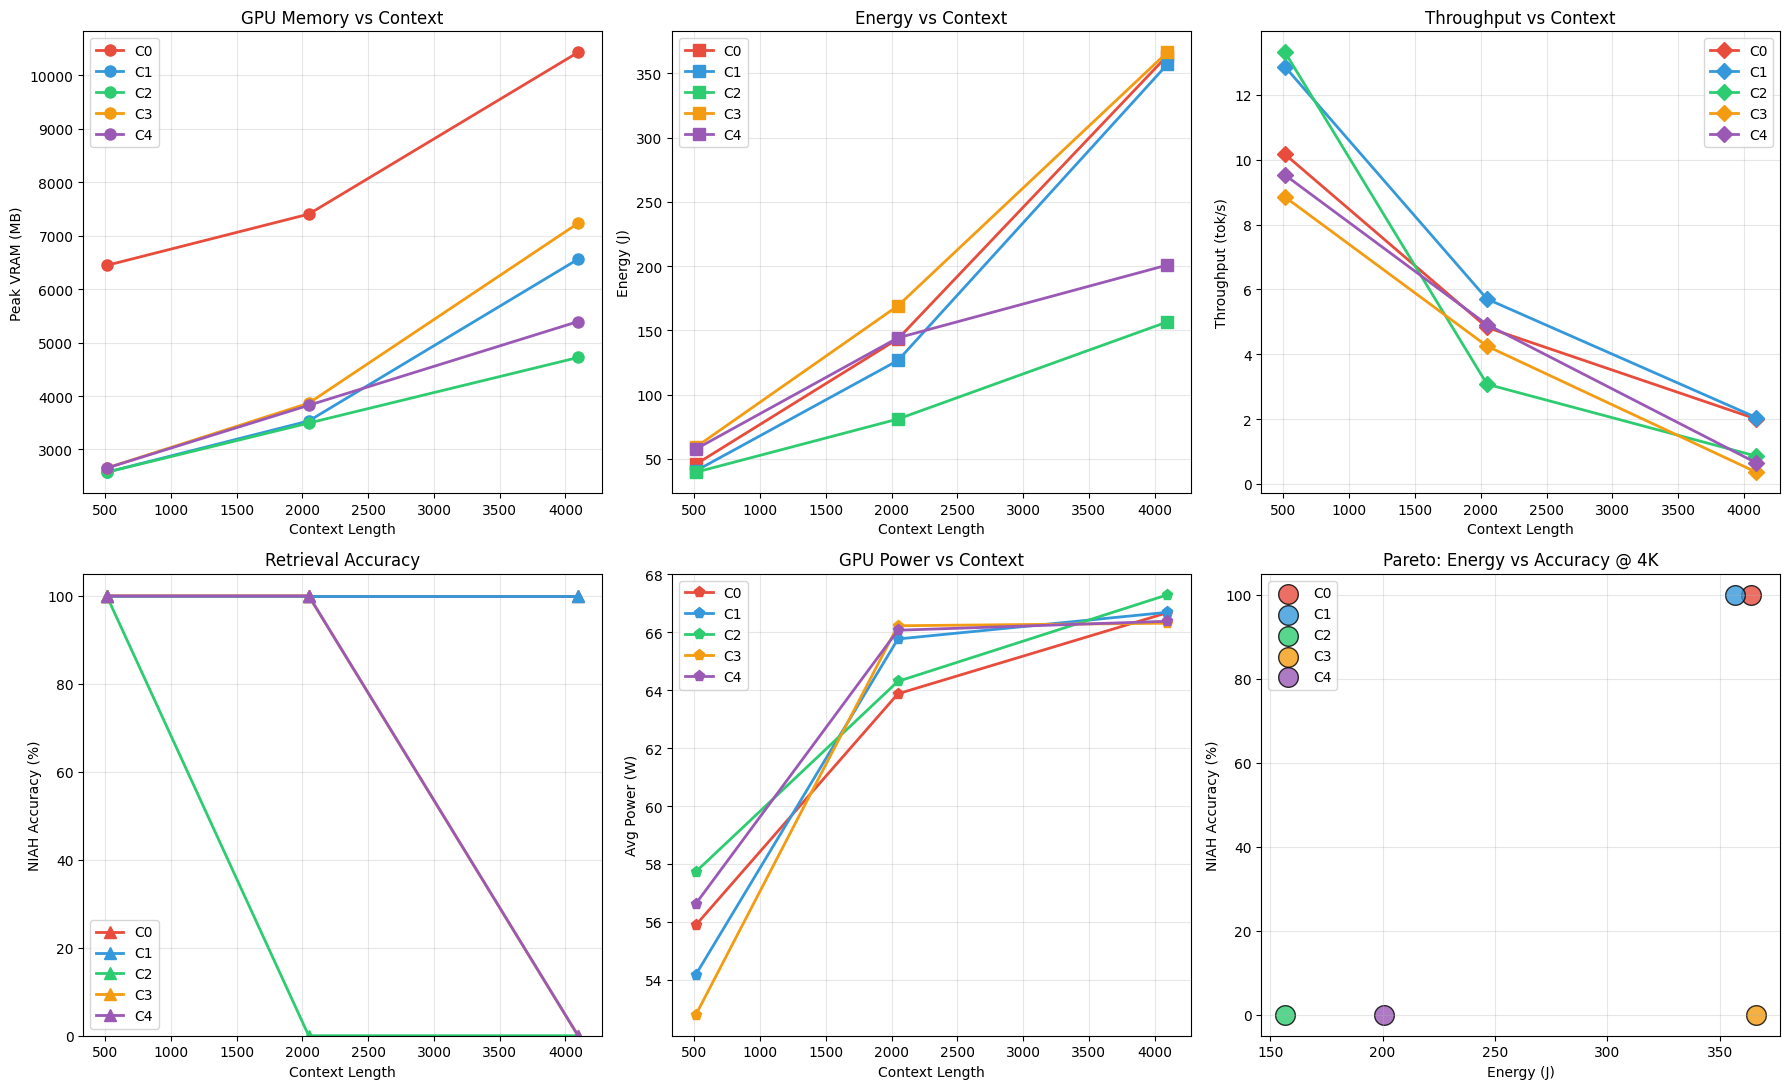


=== Summary Table ===


total_s  energy_j  vram_peak_mb  avg_power_w correct
config context                                                      
C0     512          1.0      45.8        6442.2         55.9    100%
       2048         2.3     143.3        7401.1         63.9    100%
       4096         5.5     363.8       10426.1         66.7    100%
C1     512          0.8      40.7        2574.7         54.2    100%
       2048         1.9     126.5        3533.6         65.8    100%
       4096         5.4     357.0        6558.6         66.7    100%
C2     512          0.8      39.6        2574.7         57.7    100%
       2048         1.3      81.0        3494.2         64.3      0%
       4096         2.3     156.6        4720.3         67.3      0%
C3     512          1.1      59.2        2652.5         52.8    100%
       2048         2.6     169.1        3866.0         66.2    100%
       4096         5.5     366.4        7230.6         66.3      0%
C4     512          1.0      57.6        2652.5         56.6    100%
       2048         2.2     144.2        3826.7         66.1    100%
       4096         3.1     200.8        5392.2         66.4      0%

In [11]:
df = pd.read_csv('ablation_results.csv')
df_valid = df[df['correct'].notna()]  # exclude OOM rows

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
order = ['C0', 'C1', 'C2', 'C3', 'C4']
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6']

# 1. VRAM
ax = axes[0, 0]
for cfg, c in zip(order, colors):
    d = df_valid[df_valid['config'] == cfg]
    if not d.empty:
        means = d.groupby('context')['vram_peak_mb'].mean()
        ax.plot(means.index, means.values, 'o-', label=cfg, color=c, lw=2, ms=8)
ax.set(xlabel='Context Length', ylabel='Peak VRAM (MB)', title='GPU Memory vs Context')
ax.legend(); ax.grid(alpha=0.3)

# 2. Energy
ax = axes[0, 1]
for cfg, c in zip(order, colors):
    d = df_valid[df_valid['config'] == cfg]
    if not d.empty:
        means = d.groupby('context')['energy_j'].mean()
        ax.plot(means.index, means.values, 's-', label=cfg, color=c, lw=2, ms=8)
ax.set(xlabel='Context Length', ylabel='Energy (J)', title='Energy vs Context')
ax.legend(); ax.grid(alpha=0.3)

# 3. Throughput
ax = axes[0, 2]
for cfg, c in zip(order, colors):
    d = df_valid[df_valid['config'] == cfg]
    if not d.empty:
        g = d.groupby('context')[['output_tokens', 'total_s']].mean()
        tok_s = g['output_tokens'] / g['total_s']
        ax.plot(tok_s.index, tok_s.values, 'D-', label=cfg, color=c, lw=2, ms=8)
ax.set(xlabel='Context Length', ylabel='Throughput (tok/s)', title='Throughput vs Context')
ax.legend(); ax.grid(alpha=0.3)

# 4. NIAH
ax = axes[1, 0]
for cfg, c in zip(order, colors):
    d = df_valid[df_valid['config'] == cfg].groupby('context')['correct'].mean() * 100
    if not d.empty:
        ax.plot(d.index, d.values, '^-', label=cfg, color=c, lw=2, ms=8)
ax.set(xlabel='Context Length', ylabel='NIAH Accuracy (%)', title='Retrieval Accuracy')
ax.legend(); ax.grid(alpha=0.3); ax.set_ylim(0, 105)

# 5. Power
ax = axes[1, 1]
for cfg, c in zip(order, colors):
    d = df_valid[df_valid['config'] == cfg]
    if not d.empty:
        means = d.groupby('context')['avg_power_w'].mean()
        ax.plot(means.index, means.values, 'p-', label=cfg, color=c, lw=2, ms=8)
ax.set(xlabel='Context Length', ylabel='Avg Power (W)', title='GPU Power vs Context')
ax.legend(); ax.grid(alpha=0.3)

# 6. Pareto @ 8K
ax = axes[1, 2]
for cfg, c in zip(order, colors):
    sub = df_valid[(df_valid['config'] == cfg) & (df_valid['context'] == 4096)]
    if not sub.empty:
        ax.scatter(sub['energy_j'].mean(), sub['correct'].mean() * 100,
                   s=200, label=cfg, color=c, alpha=0.8, edgecolors='black')
ax.set(xlabel='Energy (J)', ylabel='NIAH Accuracy (%)', title='Pareto: Energy vs Accuracy @ 4K')
ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('ablation_results.png', dpi=150, bbox_inches='tight')
plt.show()

# Summary
print('\n=== Summary Table ===')
summary = df_valid.groupby(['config', 'context']).agg({
    'total_s': 'mean', 'energy_j': 'mean', 'vram_peak_mb': 'mean',
    'avg_power_w': 'mean', 'correct': lambda x: f"{x.mean()*100:.0f}%",
}).round(1)
display(summary)

## 9. Statistical Tests

In [12]:
from scipy import stats

d = df_valid[df_valid['context'] == 4096]
if not d.empty:
    print('Paired t-tests: Energy (J) @ 4096\n')
    for c1, c2 in [('C0', 'C1'), ('C1', 'C2'), ('C1', 'C3'), ('C1', 'C4')]:
        e1 = d[d['config'] == c1]['energy_j'].values
        e2 = d[d['config'] == c2]['energy_j'].values
        if len(e1) == len(e2) and len(e1) > 0:
            t, p = stats.ttest_rel(e1, e2)
            sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'n.s.'
            print(f'  {c1} vs {c2}: t={t:.2f}, p={p:.4f} {sig}')
        else:
            print(f'  {c1} vs {c2}: insufficient data')
    print('\nBonferroni-adjusted alpha = 0.05 / 4 = 0.0125')
else:
    print('No 4096-token data available for statistical tests.')

Paired t-tests: Energy (J) @ 4096

  C0 vs C1: t=12.77, p=0.0061 **
  C1 vs C2: t=73.88, p=0.0002 ***
  C1 vs C3: t=-2.54, p=0.1266 n.s.
  C1 vs C4: t=20.03, p=0.0025 **

Bonferroni-adjusted alpha = 0.05 / 4 = 0.0125
